In [208]:
# BRAIN TUMOR DETECTION


In [209]:
import pandas as pd
import numpy as np
import os

In [210]:
from keras.models import Sequential
from keras.layers import Conv2D,MaxPool2D,Flatten,Dense,Dropout

In [211]:
from skimage.io import imread
from skimage.transform import resize

In [212]:
os.listdir('/content/drive/MyDrive/Brain Tumor')

['Training', 'Testing']

In [213]:
# list contents in training,
os.listdir('/content/drive/MyDrive/Brain Tumor/Training')

['meningioma', 'notumor', 'glioma', 'pituitary']

In [214]:
# testing
os.listdir('/content/drive/MyDrive/Brain Tumor/Testing')

['meningioma', 'notumor', 'pituitary', 'glioma']

In [215]:
# no of imgs in each folders
len(os.listdir('/content/drive/MyDrive/Brain Tumor/Training/glioma'))

1400

In [216]:
len(os.listdir('/content/drive/MyDrive/Brain Tumor/Training/meningioma'))

1400

In [217]:
len(os.listdir('/content/drive/MyDrive/Brain Tumor/Training/notumor'))

1400

In [218]:
len(os.listdir('/content/drive/MyDrive/Brain Tumor/Training/pituitary'))

1400

In [219]:
len(os.listdir('/content/drive/MyDrive/Brain Tumor/Testing/glioma'))

400

In [220]:
len(os.listdir('/content/drive/MyDrive/Brain Tumor/Testing/meningioma'))

400

In [221]:
len(os.listdir('/content/drive/MyDrive/Brain Tumor/Testing/pituitary'))

400

In [222]:
len(os.listdir('/content/drive/MyDrive/Brain Tumor/Testing/notumor'))

400

In [223]:
# i/p , o/p
# training

xtrain = []
ytrain = []


In [224]:
datadir = '/content/drive/MyDrive/Brain Tumor/Training'

In [225]:
categories = sorted(['meningioma', 'notumor', 'glioma', 'pituitary'])

In [184]:
for i in categories:
  path = os.path.join(datadir,i)

  for img in os.listdir(path):

    img_arr = imread(os.path.join(path,img))

    img_res = resize(img_arr,(150,150,1))# no need of flatten()

    xtrain.append(img_res)

    ytrain.append(categories.index(i))
  print('completed')



completed
completed
completed
completed


In [185]:
# testing

xtest = []
ytest = []

In [186]:
datadir1 = '/content/drive/MyDrive/Brain Tumor/Testing'

In [187]:
categories1 = sorted(['meningioma', 'notumor', 'glioma', 'pituitary'])

In [188]:
for j in categories1:
  path = os.path.join(datadir1,j)

  for img in os.listdir(path):

    img_arr1 = imread(os.path.join(path,img))

    img_res1 = resize(img_arr1,(150,150,1))# no need of flatten()

    xtest.append(img_res1)

    ytest.append(categories1.index(j))
  print('completed')

completed
completed
completed
completed


In [189]:
# converting lists into array
xtrain = np.array(xtrain)
ytrain = np.array(ytrain)

xtest = np.array(xtest)
ytest = np.array(ytest)

In [190]:
# model = Sequential()

In [191]:
# model.add(Conv2D(32,(3,3),input_shape =(150,150,1),activation ='relu'))

In [192]:
# model.add(MaxPool2D(2,2))

In [193]:
# model.add(Flatten())

In [194]:
# model.add(Dense(100,activation = 'relu'))

In [195]:
# model.add(Dense(50,activation = 'relu'))

In [196]:
# model.add(Dense(25,activation = 'relu'))

In [197]:
# model.add(Dense(4,activation ='softmax'))

In [198]:
# compiling
# model.compile(optimizer='adam',
              # loss='sparse_categorical_crossentropy',
              # metrics=['accuracy'])

In [199]:
# training
# model.fit(xtrain,ytrain,epochs=10,batch_size = 500)

In [200]:
# import matplotlib.pyplot as plt
# history = model.fit(xtrain,ytrain,validation_data=(xtest, ytest),epochs=10,batch_size=100)
# plt.plot(history.history['accuracy'], label='train')
# plt.plot(history.history['val_accuracy'], label='validation')
# plt.legend()
# plt.show()

In [201]:
model = Sequential()
model.add(Conv2D(32, (3,3), activation='relu', input_shape=(150,150,1)))  # find edges/patterns
model.add(MaxPool2D(2,2))                                                  # shrink the image
model.add(Conv2D(64, (3,3), activation='relu'))                            # find bigger patterns
model.add(MaxPool2D(2,2))
model.add(Flatten())                                                       # 2D to 1D
model.add(Dense(128, activation='relu'))                                   # decision layer
model.add(Dropout(0.5))                                                    # avoid memorizing
model.add(Dense(4, activation='softmax'))                                  # 4 classes

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 148, 148, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 82944)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │    10,616,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,636,292 (40.57 MB)

 Trainable params: 10,636,292 (40.57 MB)

 Non-trainable params: 0 (0.00 B)

In [202]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(xtrain, ytrain,
                    validation_data=(xtest, ytest),
                    epochs=10, batch_size=32)

Epoch 1/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.7005 - loss: 0.7440 - val_accuracy: 0.7412 - val_loss: 0.7397
Epoch 2/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.8377 - loss: 0.4299 - val_accuracy: 0.8075 - val_loss: 0.6711
Epoch 3/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.8804 - loss: 0.3233 - val_accuracy: 0.7894 - val_loss: 0.7230
Epoch 4/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.9075 - loss: 0.2489 - val_accuracy: 0.8163 - val_loss: 0.8086
Epoch 5/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.9343 - loss: 0.1804 - val_accuracy: 0.8600 - val_loss: 0.7550
Epoch 6/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.9475 - loss: 0.1375 - val_accuracy: 0.8637 - val_loss: 0.7586
Epoch 7/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.9559 - loss: 0.1277 - val_accuracy: 0.8725 - val_loss: 0.7271
Epoch 8/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.9623 - loss: 0.1039 - val_acc

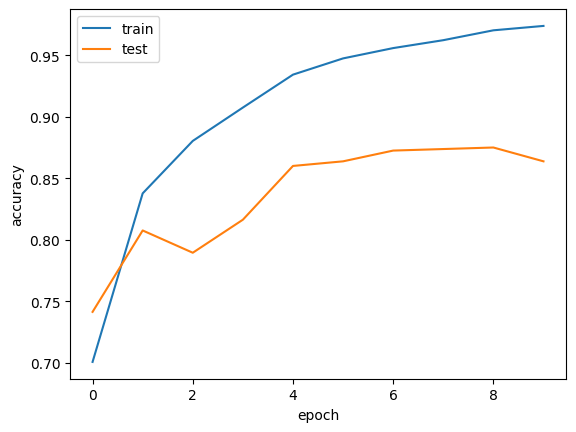

In [203]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='test')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend()
plt.show()

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=uint8)
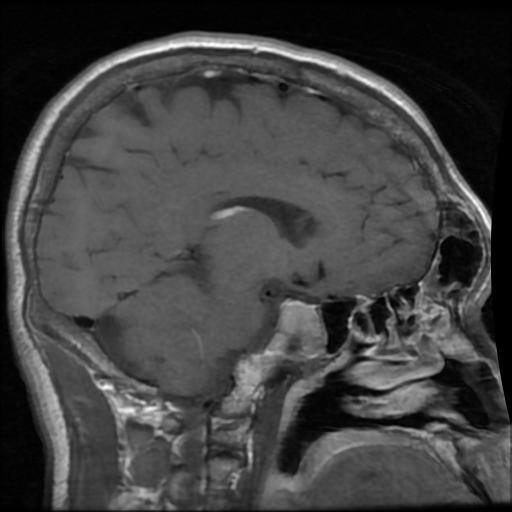

In [226]:
img ='/content/drive/MyDrive/Brain Tumor/Testing/pituitary/Te-pi_10.jpg'
img1 = imread(img)
img1

In [227]:
img2 = resize(img1,(1,150,150,1))
ypred = (model.predict(img2))
(ypred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step


array([[0.15951358, 0.13978426, 0.06491793, 0.63578427]], dtype=float32)

In [228]:

op = np.argmax(ypred)
op

np.int64(3)

In [229]:

categories1[op]

'pituitary'